# 05 — Финальная оценка

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from simulator import *
from agents import *
from experiments import *
assert Path('data/processed.npz').exists(), 'Сначала выполните data_pipeline.py'
data=load_data()
plt.rcParams.update({'figure.dpi':110,'axes.grid':True,'grid.alpha':.2})


Сначала фиксируются стратегия baseline, Q-таблица, веса DQN и параметры в results/frozen_selection.json. Затем открываются последние 48 часов. Стоимость, перегрузка, объём переноса и среднее число шардов показываются отдельно. Все фиксированные варианты приведены для контекста; основное сравнение — с фиксированным вариантом, выбранным на validation.

Дополнительно приведена идеальная нижняя граница: динамическая программа со знанием всех будущих запросов. Это не реальный соперник и не результат обучения. Сравнение трёх seed DQN выбранной конфигурации показывает чувствительность к начальным весам; мы не перевыбираем seed по test.

In [2]:
# Повторный запуск воспроизводит оценку замороженных моделей; обучение не меняется.
summary=evaluate()
display(summary.round(3))
display(pd.read_csv('results/dqn/test_seeds.csv'))
print('Идеальная offline-граница:',Path('results/oracle.json').read_text())

Final test complete; no retuning.


,cost,server_cost,overload_cost,migration_cost,overloaded_slots,excess_requests,moved_mb,mean_shards,changes,selected_on_validation
fixed_2,2607.021,384.0,2223.021,0.000,189.0,601216.0,0.000,2.000,0.0,False
fixed_3,898.045,576.0,322.045,0.000,73.0,87097.0,0.000,3.000,0.0,False
fixed_4,818.046,768.0,50.046,0.000,14.0,13535.0,0.000,4.000,0.0,False
fixed_5,970.516,960.0,10.516,0.000,4.0,2844.0,0.000,5.000,0.0,False
fixed_6,1153.438,1152.0,1.438,0.000,2.0,389.0,0.000,6.000,0.0,True
fixed_7,1344.000,1344.0,0.000,0.000,0.0,0.0,0.000,7.000,0.0,False
fixed_8,1536.000,1536.0,0.000,0.000,0.0,0.0,0.000,8.000,0.0,False
threshold,929.842,908.0,15.936,5.906,4.0,4310.0,30.542,4.729,6.0,True
q_learning,1087.378,593.0,433.211,61.166,74.0,117162.0,316.329,3.089,49.0,True
dqn,779.103,632.0,120.632,26.471,46.0,32625.0,136.899,3.292,23.0,True


,seed,cost,server_cost,overload_cost,migration_cost,overloaded_slots,excess_requests,moved_mb,mean_shards,changes
0,7,779.103437,632.0,120.632280,26.471158,46,32625,136.898674,3.291667,23
1,42,782.423850,609.0,141.504899,31.918951,52,38270,165.072569,3.171875,27
2,123,759.087017,617.0,124.925125,17.161893,49,33786,88.754725,3.213542,15


Идеальная offline-граница: {
  "cost": 681.8771729263583,
  "description": "Perfect future offline lower bound, not an online strategy"
}


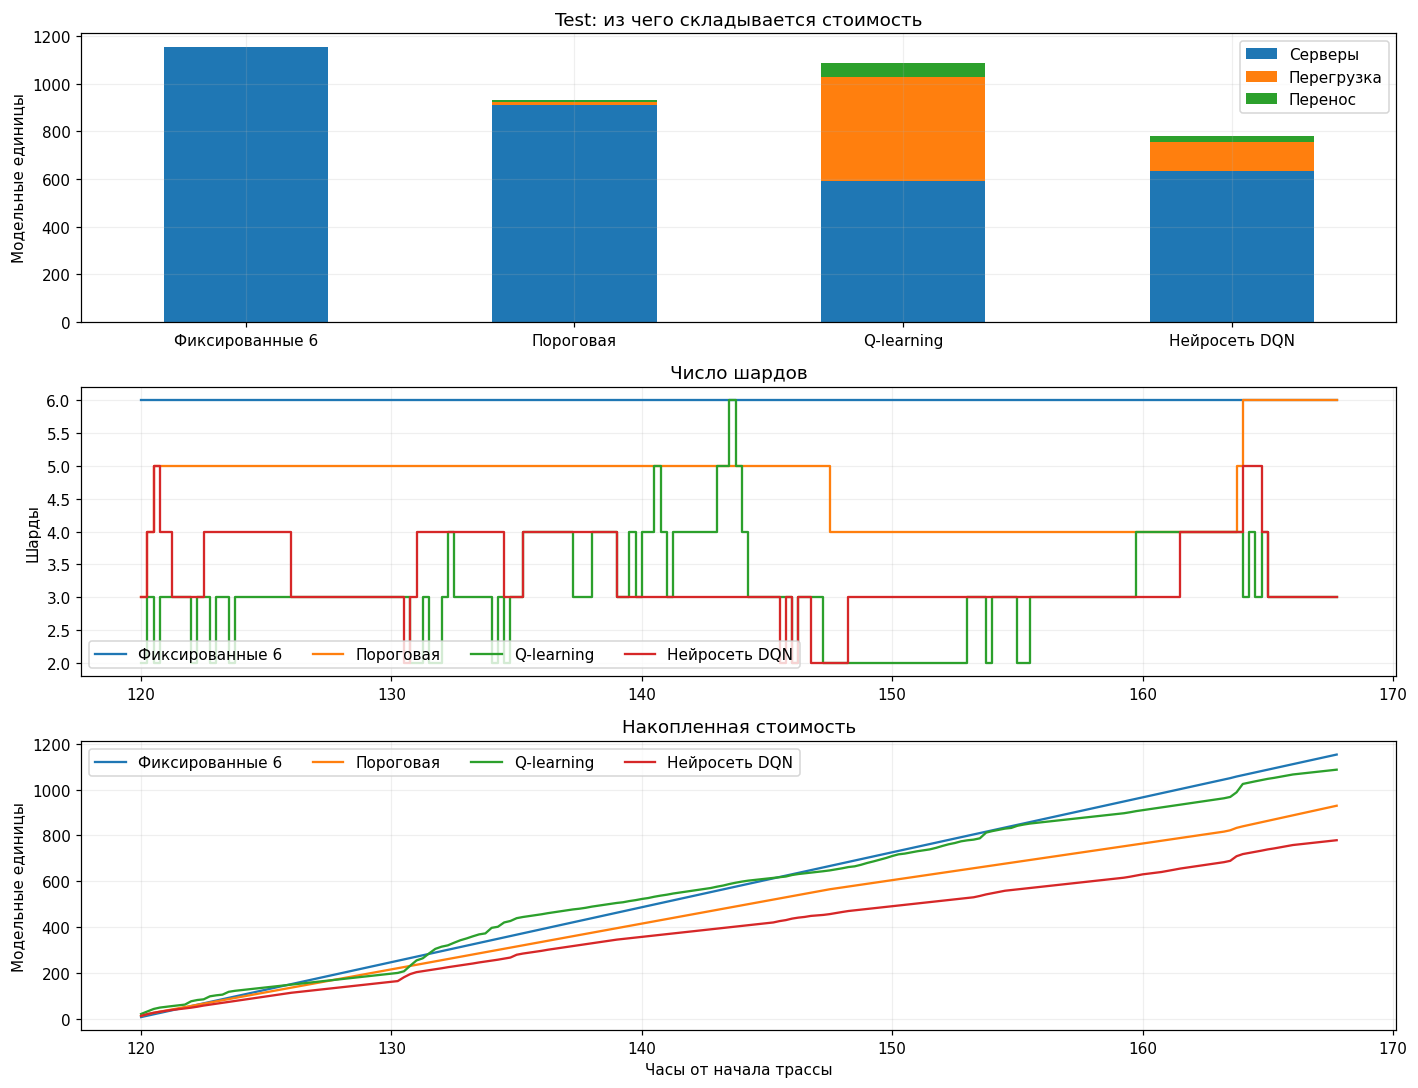

In [3]:
base=json.loads(Path('results/baseline_selection.json').read_text())
names=[base['fixed'],'threshold','q_learning','dqn']
labels={base['fixed']:'Фиксированные 6', 'threshold':'Пороговая', 'q_learning':'Q-learning', 'dqn':'Нейросеть DQN'}
fig,axes=plt.subplots(3,1,figsize=(13,10))
summary.loc[names,['server_cost','overload_cost','migration_cost']].rename(index=labels,columns={'server_cost':'Серверы','overload_cost':'Перегрузка','migration_cost':'Перенос'}).plot.bar(stacked=True,ax=axes[0],rot=0)
axes[0].set(title='Test: из чего складывается стоимость',ylabel='Модельные единицы')
for name in names:
    trace=pd.read_csv('results/test_'+name+'.csv')
    axes[1].step(trace.hour,trace.shards,where='post',label=labels[name])
    axes[2].plot(trace.hour,trace.cost.cumsum(),label=labels[name])
axes[1].set(title='Число шардов',ylabel='Шарды');axes[1].legend(ncol=4)
axes[2].set(title='Накопленная стоимость',xlabel='Часы от начала трассы',ylabel='Модельные единицы');axes[2].legend(ncol=4)
fig.tight_layout();fig.savefig('results/comparison.png',dpi=150);plt.show()

In [4]:
reference=summary.loc[base['fixed'],'cost'];neural=summary.loc['dqn','cost']
print(f'DQN относительно выбранного фиксированного baseline: {(reference-neural)/reference*100:.2f}% экономии (отрицательное значение — проигрыш).')
print('По сравнению с пороговой стратегией:',round((summary.loc['threshold','cost']-neural)/summary.loc['threshold','cost']*100,2),'%')

DQN относительно выбранного фиксированного baseline: 32.45% экономии (отрицательное значение — проигрыш).
По сравнению с пороговой стратегией: 16.21 %


В докладе нельзя трактовать условную стоимость как деньги или миллисекунды. Для вывода о преимуществе ИИ нужны новые недели и независимые кластеры, а для практической производительности — измерения реального сервиса. Горячий ключ остаётся на одном шарде: расширение JCH само по себе не делит его нагрузку. Поражение сильной пороговой стратегии или равенство с ней также являются результатом исследования.